# A learned high-level policy: which step to take next

The robot's stack is: perception (camera → `ShelfEstimate`) → **which step to take** → the steps themselves
(plans, IK, collision checks, and optionally the residual PPO during contact). This notebook is about the
middle layer.

Today that layer is hand-written rules (`Episode.next_step`). If a neighbour leans in, stand it up. If the
gap is short, widen it, or shove when the fingers don't fit. Otherwise insert. Retry counts are fixed, and
a jammed book ends the episode. `bila/control/high_level.py` replaces that choice with a learned policy.
The skills are unchanged. It adds one skill, so that the policy can **replan when the robot gets stuck**.

1. **The decision problem**: actions, features, what is allowed when.
2. **The data**: episodes of the rules with random deviations.
3. **Fitted Q iteration**: learning from those episodes offline.
4. **What the policy learned**: Q-values in a marginal gap.
5. **Test**: rules against the policy on 100 held-out rows, paired.
6. **The cart**: the same comparison with the real camera pipeline.
7. **What this says, and what to try next.**

The notebook only reads results. The commands that made them are in section 2, and the cells run in
seconds.

In [1]:
import sys, json, pathlib, collections
ROOT = pathlib.Path.cwd().parent
sys.path.insert(0, str(ROOT))
import numpy as np
import matplotlib.pyplot as plt
from bila.control import high_level as hl
load = lambda name: [json.loads(l) for l in open(ROOT / "results" / name)]
seq = lambda r: [hl.ACTIONS[s[2]] for s in r["steps"]]
how = lambda r: "placed" if r.get("success") else (r.get("skipped") or r.get("error") or "inserted, not placed")

## 1. The decision problem

**Actions** are the skills `insert_book.Episode` already has, plus two new ones:

| action | what it does |
|---|---|
| `insert` | take the book, slide it in, let go, push it home. Ends the episode, unless it jams at the entrance |
| `widen` | push a neighbour aside to the book + `GAP_MARGIN` (6 mm), as the rules do |
| `widen_more` | **new**: widen to the book + 10 mm. Room for what the camera got wrong |
| `shove` | shove the touching neighbour, and the books beyond it, into the row's free space |
| `stand_up_left/right` | stand a leaning neighbour back up |
| `set_aside` | **new**: after a jam, back the book out, put it back where it came from (the tray in the cart), and look again. The policy then decides again |
| `give_up` | leave the slot for the librarian |

`widen_more` comes from `docs/calibration-and-insertion.md`. Without the catalogue, the camera saw books too
thick, so the rules widened more, and that accidental margin covered the calibration error. Here the policy
can choose that margin on purpose.

**Features** are 15 numbers, all from the camera's estimate or the episode's history:

In [2]:
for name in hl.FEATURES:
    print(" ", name)

  lean_left_deg
  lean_right_deg
  gap_spare_mm
  widen_spare_mm
  fingers_spare_mm
  room_left_mm
  room_right_mm
  book_mm
  stand_ups
  widens
  shoves
  jams
  steps
  last_did
  holding


**What is allowed when** (`valid`): each skill's own preconditions and the rules' retry caps. Without them, a
policy could loop forever or try a skill that can't work. Some examples:
- `insert` only if the estimated gap is at least the book's thickness;
- `shove` only once, and only when the fingers don't fit;
- with a jammed book in the hand, only `set_aside` or `give_up`;
- at most 10 steps.

The rules themselves are a policy in this loop (`Rules`), so both are run and scored the same way.

## 2. The data

`collect` ran the rules with 30% random valid steps (`EpsilonRules`; never a random `give_up`, which teaches
nothing) on 60 rows of each scenario, seeds 5000–5059. Perception is `noisy-learned`: the truth plus the
measured errors of the learned-mask camera, with no rendering, so the hundreds of episodes are affordable.

```bash
uv run python -m bila.control.high_level collect --perception noisy-learned --seeds 5000:5060 --eps 0.3 \
    --out results/hl_train.jsonl --workers 4
uv run --group rl python -m bila.control.high_level fit --data results/hl_train.jsonl --out runs/hl/q.npz
# the test: the rules and the policy on held-out rows, seeds 0-24
uv run python -m bila.control.high_level collect --perception noisy-learned --seeds 0:25 --eps 0 --out results/hl_eval_rules.jsonl
uv run python -m bila.control.high_level collect --perception noisy-learned --seeds 0:25 --policy runs/hl/q.npz --out results/hl_eval_q.jsonl
```

In [3]:
train = load("hl_train.jsonl")
for s in ("clear", "tight", "leaning", "packed"):
    rs = [r for r in train if r["scenario"] == s]
    print(f"{s:8} placed {sum(bool(r.get('success')) for r in rs):2d}/{len(rs)}")
print("\ndecisions:", sum(len(r["steps"]) for r in train), " actions taken:",
      dict(collections.Counter(a for r in train for a in seq(r)).most_common()))
jammed = [r for r in train if r.get("jams")]
print(f"episodes with a jam: {len(jammed)}, recovered after set_aside: {sum(bool(r.get('success')) for r in jammed)}")
print("\nwhy the others failed:")
for k, n in collections.Counter(how(r) for r in train if not r.get("success")).most_common():
    print(f"  {n:3d}  {k}")

clear    placed 59/60
tight    placed 44/60
leaning  placed 53/60
packed   placed 33/60

decisions: 562  actions taken: {'insert': 210, 'widen': 125, 'shove': 75, 'widen_more': 63, 'give_up': 31, 'stand_up_right': 29, 'stand_up_left': 24, 'set_aside': 5}
episodes with a jam: 4, recovered after set_aside: 2

why the others failed:
   13  inserted, not placed
   11  the gap stayed narrower than the book
   11  not enough free space in the row for the book
    5  No arm configuration does the whole sequence without nearing a joint limit or running into the shelf
    2  the fingers can't reach a neighbour with room behind it
    2  No collision-free joint move to the next arm configuration
    1  only -12 mm of the neighbour to pinch
    1  the high-level policy gave up
    1  only -9 mm of the neighbour to pinch
    1  only -2 mm of the neighbour to pinch
    1  only -4 mm of the neighbour to pinch
    1  only -8 mm of the neighbour to pinch
    1  only -5 mm of the neighbour to pinch


Two things in this data limit what can be learned:

- **Jams are rare** (4 in 240 episodes), so `set_aside` hardly gets tried. The policy can't learn much about
  recovering from jams.
- **Many failures can't be changed by choosing steps**: an arm that can't reach, a gap still short after
  every widening the caps allow, a book left proud by the push. The choice of step only matters in the
  remaining cases.

## 3. Fitted Q iteration

An episode is a short sequence of (features, valid actions, action), with reward 1 at the end if the book is
placed, and −0.02 per step. Fitted Q iteration learns `Q(s, a)`, the expected return of taking `a` in `s`
and acting well afterwards, from that fixed data:

    repeat 8 times:   target = r + max over the next state's valid actions of Q(s', a')   (r alone at the end)
                      Q <- a small MLP (15 → 64 → 64 → 8) fitted to the targets

Being offline is the point. Each episode costs 30–100 s of simulation, so the policy is fitted to whatever
data exists, and new data can be added without starting over. The policy is then `argmax` of `Q` over the
valid actions (`QPolicy`, numpy only, so the cart doesn't need torch).

## 4. What the policy learned

A tight row's state, varied along one feature: how much wider the gap is than book + 6 mm (`widen_spare_mm`;
negative means short). The plot shows Q for the actions that matter there.

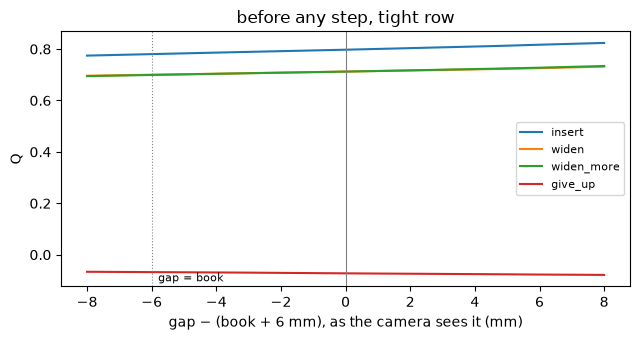

In [4]:
q = hl.QPolicy(ROOT / "runs/hl/q.npz")
base = dict.fromkeys(hl.FEATURES, 0.0)
base.update(book_mm=40.0, fingers_spare_mm=15.0, room_left_mm=40.0, room_right_mm=40.0, last_did=1.0)
spare = np.linspace(-8, 8, 33)
F = []
for v in spare:
    f = dict(base, widen_spare_mm=v, gap_spare_mm=v + 6.0)
    F.append([f[k] for k in hl.FEATURES])
Q = q.q(np.array(F))
plt.figure(figsize=(6.5, 3.5))
for a in ("insert", "widen", "widen_more", "give_up"):
    plt.plot(spare, Q[:, hl.ACTIONS.index(a)], label=a)
plt.axvline(0, color="grey", lw=0.8); plt.axvline(-6, color="grey", lw=0.8, ls=":")
plt.text(-5.8, plt.ylim()[0] + 0.02, "gap = book", fontsize=8)
plt.xlabel("gap − (book + 6 mm), as the camera sees it (mm)"); plt.ylabel("Q")
plt.legend(fontsize=8); plt.title("before any step, tight row"); plt.tight_layout()

Read this with care: it is one slice through 15 features, and the model was fitted on 562 decisions.
Section 5 shows what it does on real rows: it prefers `widen_more` to `widen` almost everywhere, and
inserts without widening in some clear rows.

## 5. Test: 100 held-out rows

Seeds 0–24 of each scenario. Training never used them, and nothing was tuned on them: the policy was
fitted once. Both arms run on the same rows with the same noise draws, so the comparison is row by row.

The rules arm runs through the same loop, so after a jam the rules also `set_aside` and then follow their
rules again. That makes it the rules *plus* the new recovery step, not the original `reshelve`.

In [5]:
R = {(r["scenario"], r["seed"]): r for r in load("hl_eval_rules.jsonl")}
P = {(r["scenario"], r["seed"]): r for r in load("hl_eval_q.jsonl")}
print(f"{'':9}{'rules':>7}{'policy':>8}   rows only the policy placed / only the rules placed")
for s in ("clear", "tight", "leaning", "packed"):
    ks = sorted(k for k in R if k[0] == s)
    won = [k[1] for k in ks if P[k].get("success") and not R[k].get("success")]
    lost = [k[1] for k in ks if R[k].get("success") and not P[k].get("success")]
    print(f"{s:9}{sum(bool(R[k].get('success')) for k in ks):5d}/25{sum(bool(P[k].get('success')) for k in ks):5d}/25"
          f"   {won} / {lost}")
print(f"{'all':9}{sum(bool(r.get('success')) for r in R.values()):5d}   {sum(bool(r.get('success')) for r in P.values()):5d}")
for name, d in (("rules", R), ("policy", P)):
    print(f"\n{name}: {np.mean([len(r['steps']) for r in d.values()]):.2f} steps a row;",
          dict(collections.Counter(a for r in d.values() for a in seq(r)).most_common()))

           rules  policy   rows only the policy placed / only the rules placed
clear       24/25   24/25   [] / []
tight       18/25   18/25   [] / []
leaning     21/25   21/25   [11, 12] / [3, 6]
packed      13/25   13/25   [] / []
all         76      76

rules: 2.25 steps a row; {'insert': 86, 'widen': 66, 'shove': 27, 'give_up': 18, 'stand_up_right': 14, 'stand_up_left': 11, 'set_aside': 3}

policy: 2.36 steps a row; {'insert': 88, 'widen_more': 67, 'shove': 28, 'widen': 18, 'give_up': 14, 'stand_up_left': 10, 'stand_up_right': 9, 'set_aside': 2}


In [6]:
print("rows where one placed the book and the other didn't:\n")
for k in sorted(R):
    if bool(R[k].get("success")) != bool(P[k].get("success")):
        print(f"{k[0]} {k[1]}")
        print(f"   rules : {' → '.join(seq(R[k]))}   ({how(R[k])})")
        print(f"   policy: {' → '.join(seq(P[k]))}   ({how(P[k])})")

rows where one placed the book and the other didn't:

leaning 3
   rules : stand_up_right → insert   (placed)
   policy: widen → widen_more → widen_more → insert   (inserted, not placed)
leaning 6
   rules : stand_up_left → insert   (placed)
   policy: widen_more → widen_more → insert → set_aside → widen → stand_up_left → insert   (inserted, not placed)
leaning 11
   rules : stand_up_right → widen → widen → insert → set_aside → insert → set_aside → insert → give_up   (the high-level policy gave up)
   policy: widen → insert   (placed)
leaning 12
   rules : stand_up_left → widen → widen → widen → give_up   (the gap stayed narrower than the book)
   policy: shove → stand_up_left → widen_more → insert   (placed)


**Result: a tie, 76 against 76.** The policy behaves differently on about half the rows, but the
differences cancel:

- **What it learned that helps:** shove *before* standing up when a leaner is wedged and the rules ran out
  of widenings (leaning 12), and give up less often after three widenings.
- **What it learned that hurts:** skip the stand-up and widen instead (leaning 3, 6). That works on the
  training rows often enough to look good to Q, but leaves a leaner that the book later catches.
- **What doesn't matter:** `widen_more` instead of `widen`. In this perception model the extra 4 mm neither
  helped nor hurt; both arms miss the same rows (tight 19, leaning 13 and 24) the same way.

## 6. The cart, with the real camera

The same policy in `cart_demo` (wrist camera, fiducial correction, the simulation's masks). It was trained
on a noise model, so this checks whether it transfers.

```bash
uv run python -m bila.control.cart_demo --scenario tight --seed 0 --policy runs/hl/q.npz
uv run python -m bila.viz.live_view --scenario tight --seed 0 --policy runs/hl/q.npz   # watch it
```

In [7]:
cart = collections.defaultdict(dict)
path = ROOT / "results/hl_cart.txt"
for line in open(path) if path.exists() else []:
    head, _, tail = line.partition("|")
    s, seed, mode = head.split()
    cart[(s, int(seed))][mode] = tail.strip()
for k in sorted(cart):
    for mode in ("rules", "policy"):
        if mode in cart[k]:
            print(f"{k[0]:8}{k[1]}  {mode:7}{cart[k][mode][:110]}")
ok = lambda t: t.startswith("SUCCESS")
both = [k for k in cart if len(cart[k]) == 2]
print(f"\n{len(both)} scenes with both: rules placed {sum(ok(cart[k]['rules']) for k in both)}, "
      f"policy {sum(ok(cart[k]['policy']) for k in both)}")

clear   0  rules  SUCCESS [insert]: tilt 0.0 deg, spine +9.2 mm from the neighbour's, released
clear   0  policy SUCCESS [insert]: tilt 0.0 deg, spine +9.2 mm from the neighbour's, released
clear   1  rules  SUCCESS [insert]: tilt 0.0 deg, spine +0.8 mm from the neighbour's, released
clear   1  policy SUCCESS [insert]: tilt 0.0 deg, spine +0.8 mm from the neighbour's, released
clear   2  rules  SUCCESS [insert]: tilt 0.0 deg, spine -3.4 mm from the neighbour's, released
clear   2  policy SUCCESS [insert]: tilt 0.0 deg, spine -3.4 mm from the neighbour's, released
leaning 0  rules  SUCCESS [stand_up, insert]: tilt 0.0 deg, spine +4.7 mm from the neighbour's, released
leaning 0  policy SUCCESS [stand_up_left, insert]: tilt 0.0 deg, spine +4.7 mm from the neighbour's, released
leaning 1  rules  SUCCESS [stand_up, insert]: tilt 0.0 deg, spine +5.3 mm from the neighbour's, released
leaning 1  policy SUCCESS [widen_more, widen_more, insert]: tilt 0.0 deg, spine +5.8 mm from the neighbour's, 

**Cart result: 10 of 12 for both.** The policy transfers from the noise model to the rendered camera. It
places the same scenes, and packed 0 and 1 fail for both on arm reach ("no collision-free joint move"), as
they did before any of this. One difference shows: in the tight rows it uses one `widen_more` where the
rules widen two or three times (tight 0: 2 steps against 4), which saves a widening's time per book. In
leaning 1 it again skipped the stand-up, and here that worked.

## 7. What this says

- **The step choice isn't where this robot loses books.** With step choice in the policy's hands it ties the
  rules. The failures left are perception (the book left proud, the gap misjudged) and reach (no
  collision-free move). The residual on the contact moves, and better perception, are the levers for those.
- **The policy needs more data on the decisions that matter.** 562 decisions, 4 jams. Collecting more rows
  where the rules fail (a 50/50 mix, as `bila/rl/hard_cases.py` does for the residual) would teach it more
  than more easy rows.
- **The policy must not be allowed to skip safety-critical steps.** It skipped stand-ups the rules always
  take. Either keep `stand_up` mandatory when a neighbour leans past `LEAN_MIN_DEG` (a rule in `valid`), or
  penalise the outcomes it causes.
- **`set_aside` works but was rarely needed**: 4 jams in 240 training episodes, none in the 12 cart scenes.
  On the test rows it saved one (tight 20, rules arm) and failed to save two.
- **Where it does pay off: fewer steps.** In the cart's tight rows, one wider widening replaced two or three
  normal ones. A tie in placements with less time per book is a small win.

Next steps, cheapest first:
1. Make stand-up mandatory in `valid`, refit, and test on *new* held-out rows (seeds 25–49). Seeds 0–24 have
   been looked at now, so they no longer count as a test.
2. Collect from rows the rules fail on, and add `--perception camera` data (slower, but no transfer gap).
3. Keep fitted Q, but give each skill its own outcome model, e.g. P(placed | insert now): easier to inspect
   and to keep safe than one Q over all actions.